[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C3_NB06_active_rotator_mean_field.ipynb)

# Day 1 · Chapter 3 · Notebook 06 — A crowd of rotators: regimes, bursts, and a two-number model

**Goal.** In NB04 we simulated thousands of active rotators and saw that the population can be quiet, fire in
synchronous bursts, or fire asynchronously. Here we:

1. summarise the whole crowd by **one arrow** (two numbers: how aligned the units are, and where they are);
2. look at the **dynamic regimes** of the network, following Buendía et al. (2021): quiet, periodic bursting,
   irregular bursting at the border, asynchronous firing;
3. use a **two-number model** of the population (the mean field used by Rabuffo et al. 2026 as the building block of
   a whole-brain model) and see that it produces the same regimes: quiet, irregular bursts near the border, and
   **periodic bursting**;
4. see what is special about the border between quiet and bursting (the "critical" regime).

No derivations here: we use the models as tools and look at what they do.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import networks, meanfield
from src.plotting import show_movie, phase_movie
os.makedirs('../figures/videos', exist_ok=True)
REG = {'sub': 'C2', 'crit': 'C0', 'super': 'C3', 'async': '0.4'}   # colours as in Rabuffo et al. 2026: green / blue / red

## 1. A crowd of rotators, summarised by one arrow

Reminder from NB04. Each unit is a point moving on a circle (its **phase**); it fires a spike each time it passes
the top of the circle. Three knobs:

* the **tilt** $a$: how hard it is for a unit to go round. $a<1$: the unit goes round by itself (an oscillator).
  $a>1$: the unit stops at a resting point and only fires if something kicks it (an **excitable** unit, like a
  neuron at rest).
* the **noise** $\sigma$: random kicks, different for every unit;
* the **coupling** $J$: each unit is pulled towards the others.

To describe 2000 units at once we draw **one arrow**, the average of all the points on the circle (the Kuramoto
order parameter of NB04):

* its **length** $R$ (between 0 and 1): how *together* the units are. $R\approx1$: all at the same place;
  $R\approx0$: spread all around the circle;
* its **direction** $\Psi$: where the crowd is on the circle.

Watch the arrow in a population that fires in bursts. Careful with the intuition: here the arrow is **long when
the population is quiet** (everyone waits together at the resting point), and it **shrinks during a burst**: the
units leave the resting point, spread around the circle as they fire, and come back together.

In [2]:
t, Z, ph = networks.active_rotator_network(N=2000, a=1.06, J=1.0, sigma=0.499, T=150, dt=0.05, rec_dt=0.5,
                                           n_rec=2000, seed=2)
m = t >= 50
show_movie(phase_movie(t[m], ph[m], Z[m], n_show=300, stride=1, interval=60, title="2000 rotators (300 shown) and their arrow",
                       spike_phase=np.pi / 2), save_as="../figures/videos/nb06_arrow.mp4")

Left: 300 of the units (blue dots), the spike point (red star) and the arrow. Right: the length $R$ of the arrow
over time. Each dip of $R$ is a **population burst**.

## 2. The regimes of the network

Each pair (tilt $a$, noise $\sigma$) is a different population. Buendía et al. (2021) mapped what the population
does for every pair. The map below was computed in NB08 (where we will study it in detail); for now we only read it.

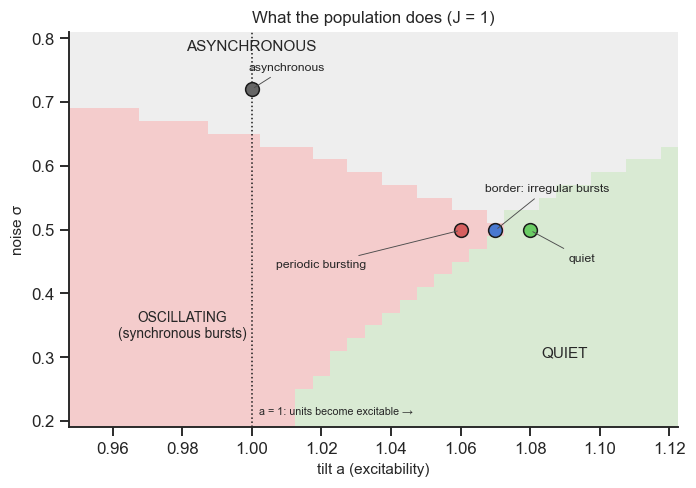

In [3]:
CACHE = os.path.join("..", "data", "cache")
pdg = dict(np.load(os.path.join(CACHE, "nb08_phase_diagram.npz")))
A_grid, S_grid = pdg["A"], pdg["S"]
regime = np.where(pdg["osc_incoherent"] > 0.05, 2, np.where(pdg["rate_incoherent"] < 0.005, 0, 1))  # 0 quiet, 1 async, 2 osc

# four example populations (J = 1; three of them along the path studied by Rabuffo et al. 2026, sigma = 0.499)
EXAMPLES = {"quiet": (1.08, 0.499, "sub"), "border: irregular bursts": (1.07, 0.499, "crit"),
            "periodic bursting": (1.06, 0.499, "super"), "asynchronous": (1.0, 0.72, "async")}

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.pcolormesh(A_grid, S_grid, regime, cmap=ListedColormap(["#d9ead3", "#eeeeee", "#f4cccc"]), shading="nearest")
ax.text(1.09, 0.3, "QUIET", ha="center", fontsize=10); ax.text(0.98, 0.33, "OSCILLATING\n(synchronous bursts)", ha="center", fontsize=9)
ax.text(1.0, 0.78, "ASYNCHRONOUS", ha="center", fontsize=10)
LABEL_AT = {"quiet": (1.095, 0.45), "border: irregular bursts": (1.085, 0.56), "periodic bursting": (1.02, 0.44), "asynchronous": (1.01, 0.75)}
for name, (a, s, key) in EXAMPLES.items():
    ax.plot(a, s, "o", ms=9, c=REG[key], mec="k", zorder=3)
    ax.annotate(name, (a, s), xytext=LABEL_AT[name], fontsize=8, ha="center", arrowprops=dict(arrowstyle="-", lw=0.6, color="0.3"))
ax.axvline(1.0, c="k", ls=":", lw=1); ax.text(1.002, 0.21, "a = 1: units become excitable →", fontsize=7)
ax.set(xlabel="tilt a (excitability)", ylabel="noise σ", title="What the population does (J = 1)")
plt.tight_layout()

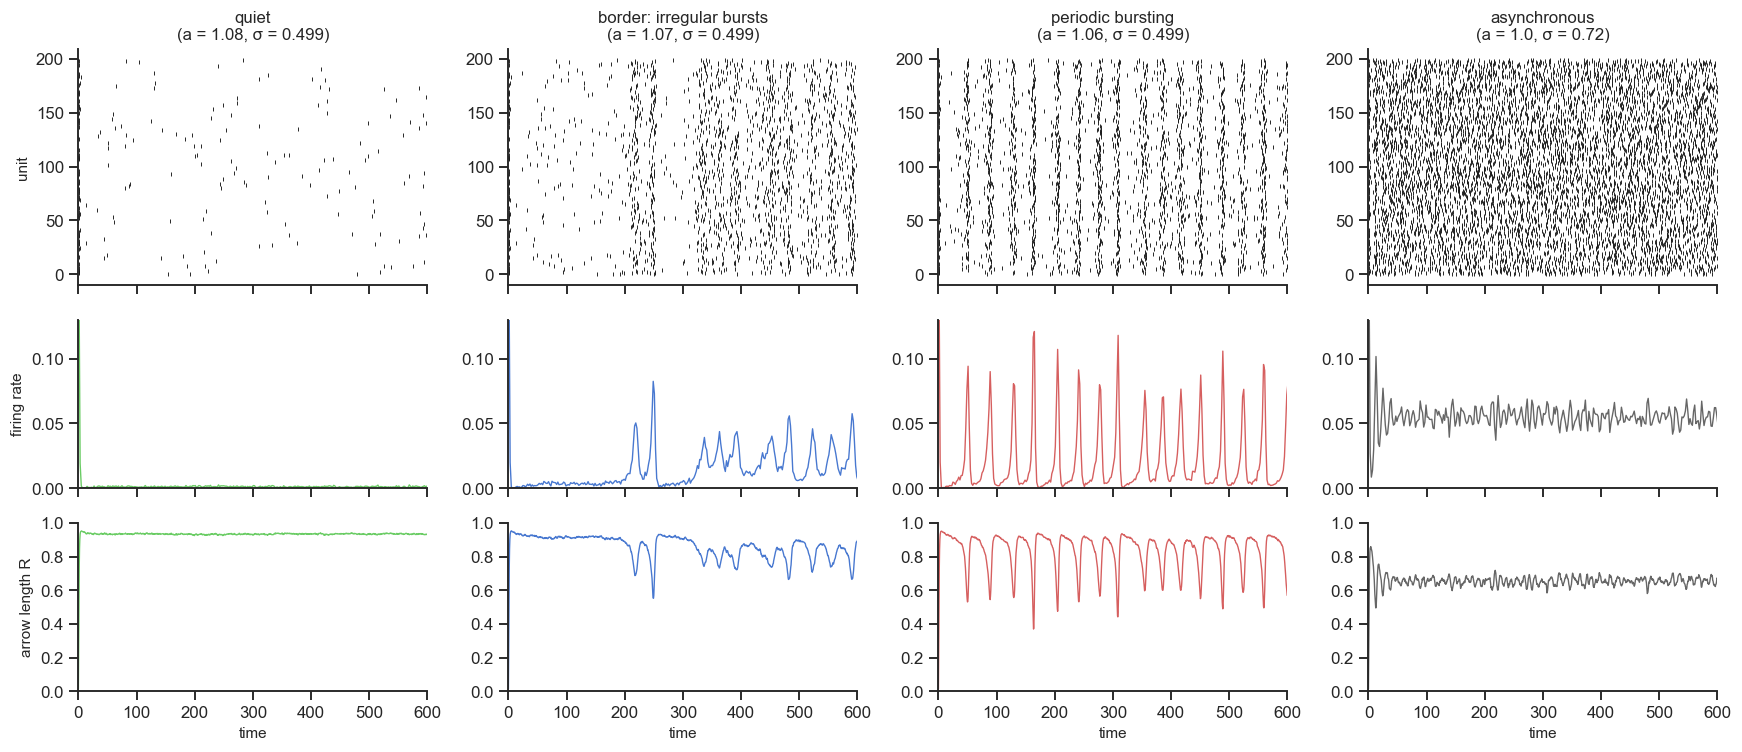

In [4]:
NET = {}
for name, (a, s, key) in EXAMPLES.items():
    NET[name] = networks.active_rotator_network(N=3000, a=a, J=1.0, sigma=s, T=1500, dt=0.05, rec_dt=0.5, n_rec=3000,
                                                seed=1, return_spikes=True, n_spk=200)

def population_rate(t, ph, n_units, bin_size=2.0):
    st, _ = networks.phase_raster(t, ph)
    edges = np.arange(0, t[-1] + 1e-9, bin_size)
    return edges[:-1] + bin_size / 2, np.histogram(st, bins=edges)[0] / n_units / bin_size

fig, ax = plt.subplots(3, 4, figsize=(16, 7), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1, 1]))
for j, (name, (a, s, key)) in enumerate(EXAMPLES.items()):
    t, Z, ph, counts, st, si = NET[name]
    keep = st < 600
    ax[0, j].plot(st[keep], si[keep], "|", c="k", ms=2, mew=0.6)
    tr, rr = population_rate(t, ph, ph.shape[1])
    ax[1, j].plot(tr, rr, c=REG[key], lw=0.9)
    ax[2, j].plot(t, np.abs(Z), c=REG[key], lw=0.9)
    ax[0, j].set(title=f"{name}\n(a = {a}, σ = {s})", ylabel="unit" if j == 0 else "")
    ax[1, j].set(ylabel="firing rate" if j == 0 else "", ylim=(0, 0.13))
    ax[2, j].set(ylabel="arrow length R" if j == 0 else "", ylim=(0, 1), xlabel="time", xlim=(0, 600))
plt.tight_layout()

Top: raster of 200 units (one row each, a mark per spike). Middle: population firing rate. Bottom: length of the
arrow.

* **Quiet** (green): the units are excitable and sit at rest; noise makes a few of them fire now and then, but the
  coupling is not strong enough to recruit the others. $R$ stays high and flat.
* **Periodic bursting** (red): the population fires in **regular synchronous bursts**: everybody fires together,
  then rests, then fires again. A collective rhythm, although each unit on its own (with this tilt and this noise)
  would not keep such a clock.
* **Border** (blue): between the two. Long quiet periods interrupted by bursts that come at **irregular** times
  and have **different sizes**. This is the regime that Buendía et al. associate with scale-free avalanches (NB08)
  and that Rabuffo et al. call **critical**.
* **Asynchronous** (grey): with strong noise every unit fires on its own schedule: high, steady firing, no
  collective rhythm, $R$ small.

Moving the tilt by only 0.01 changes the behaviour completely: the three coloured populations sit close to a
**transition**. Where exactly? We scan the tilt with the noise fixed, with long runs (20 000 time units each,
1000 units, as for the isolated populations of Rabuffo et al. 2026). For each tilt we measure:

* the **mean firing rate**;
* the **susceptibility**: how much the *slow* part of the arrow length fluctuates. We first smooth $R(t)$ over 200
  time units, which removes the fast, regular ups and downs of a rhythm and keeps only slow swings, then measure
  its variance (multiplied by the number of units). Large susceptibility = the population makes large, slow,
  irregular excursions;
* the **autocorrelation** of $R$: how similar $R$ is to itself one time unit later (close to 1 = slow fluctuations).

The runs take a few minutes, so they are precomputed in `data/cache/nb06_scan.npz` (script `dev/cache_nb06.py`);
without the file a shorter version runs here (~1 min, noisier).

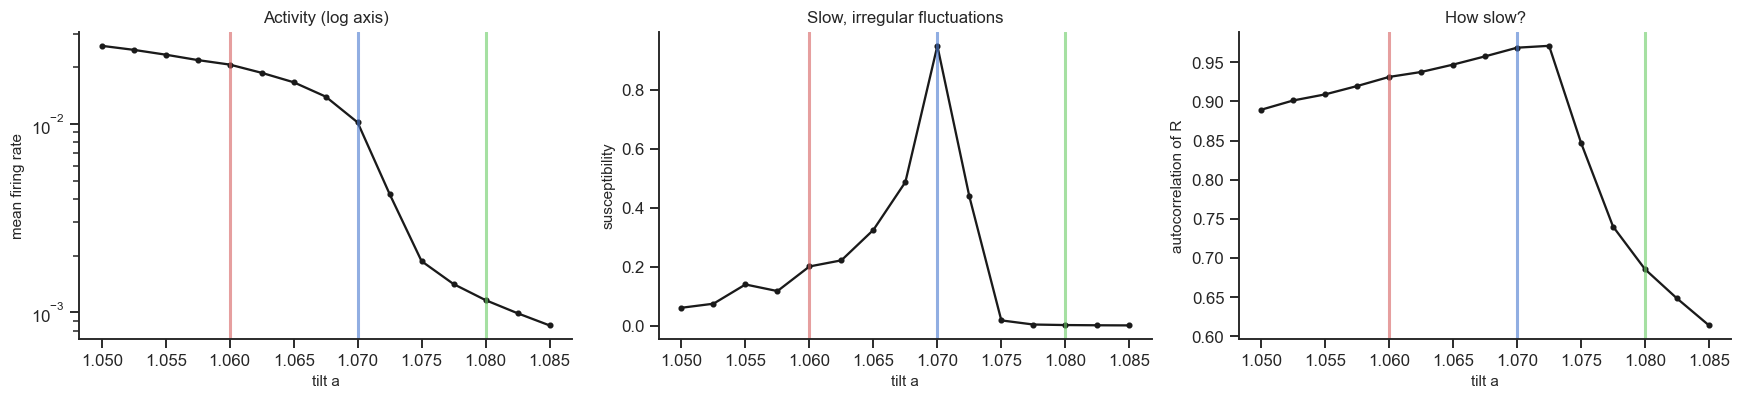

In [5]:
from scipy.signal import butter, sosfiltfilt
path = os.path.join(CACHE, "nb06_scan.npz")
if os.path.exists(path):
    scan = dict(np.load(path))
else:                                              # shorter, noisier version of dev/cache_nb06.py
    scan = {"a_scan": np.round(np.arange(1.05, 1.0851, 0.005), 4), "rate": [], "chi": [], "ac1": []}
    sos = butter(4, 1 / 200, btype="low", fs=2.0, output="sos")
    for a in scan["a_scan"]:
        t, Z, ph, counts, *_ = networks.active_rotator_network(N=1000, a=a, J=1.0, sigma=0.499, T=4000, dt=0.05,
                                                              rec_dt=0.5, n_rec=1, seed=1, return_spikes=True)
        R = np.abs(Z[t > 200]); x = R - R.mean()
        scan["rate"].append(counts[4000:].sum() / 1000 / 3800)
        scan["chi"].append(1000 * sosfiltfilt(sos, R).var())
        scan["ac1"].append(np.mean(x[:-2] * x[2:]) / x.var())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(scan["a_scan"], scan["rate"], "ko-", ms=3); ax[0].set(yscale="log", ylabel="mean firing rate", title="Activity (log axis)")
ax[1].plot(scan["a_scan"], scan["chi"], "ko-", ms=3); ax[1].set(ylabel="susceptibility", title="Slow, irregular fluctuations")
ax[2].plot(scan["a_scan"], scan["ac1"], "ko-", ms=3); ax[2].set(ylabel="autocorrelation of R", title="How slow?")
for a_ in ax:
    a_.set_xlabel("tilt a")
    for name, (a, s, key) in list(EXAMPLES.items())[:3]:
        a_.axvline(a, c=REG[key], lw=2, alpha=0.6)
plt.tight_layout()

* **Activity (left, log axis).** As the tilt increases the firing rate decreases, and between $a=1.07$ and
  $1.075$ it **drops** by a factor of five: the population falls silent.
* **Susceptibility (middle).** A sharp **peak at $a=1.07$**, the border regime (blue). There the population makes the
  largest slow, irregular excursions: long silences and bursts of all sizes. In the periodic regime (red) the
  bursts are large but regular, so once smoothed they leave little; in the quiet regime (green) there is almost
  nothing to fluctuate.
* **Autocorrelation (right).** Highest right at the border too (peak at the next point, $a=1.0725$): near the
  transition the population is at its slowest. This is **critical slowing down**, and we will meet it again in the
  two-number model below and in Chapter 4.

The peaks of susceptibility and autocorrelation are the two markers Rabuffo et al. (2026) use to locate the
critical regime of a population.

## 3. A model of the whole population in two numbers

Simulating thousands of units is expensive, and a whole-brain model needs one population per brain region. So we
would like a model that follows **only the arrow**: two numbers ($R$ and $\Psi$) instead of thousands of phases. This
is a **mean-field model** (the same idea as NB05 for the QIF neurons).

Ott & Antonsen (2008) found two equations for the arrow; for noisy rotators they are an approximation. Rabuffo et al.
(2026) used them, with a small amount of noise added to the arrow, as the model of one brain region. In the course
code it is `meanfield.ott_antonsen_noisy`. We use it as a black box: give it the tilt, the noise and the coupling;
it returns the arrow over time and the population firing rate.

We run it at the three values of the tilt used in the paper.

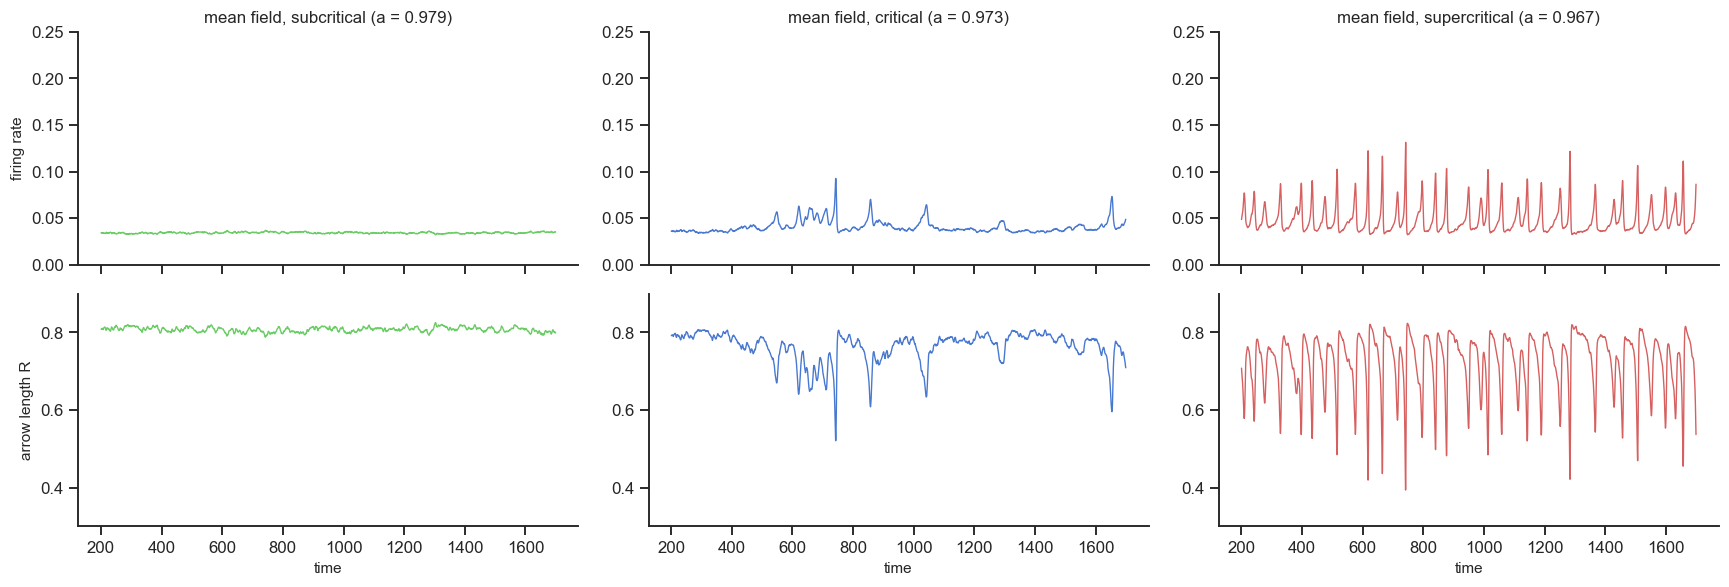

In [6]:
MF = {"subcritical": (0.979, "sub"), "critical": (0.973, "crit"), "supercritical": (0.967, "super")}
mf_runs = {name: meanfield.ott_antonsen_noisy(a=a, J=1.25, sigma=0.6725, T=3000, seed=2) for name, (a, key) in MF.items()}

fig, ax = plt.subplots(2, 3, figsize=(16, 5.5), sharex=True)
for j, (name, (a, key)) in enumerate(MF.items()):
    t, R, Psi, rate = mf_runs[name]
    m = (t > 200) & (t < 1700)
    ax[0, j].plot(t[m], rate[m], c=REG[key], lw=0.9)
    ax[1, j].plot(t[m], R[m], c=REG[key], lw=0.9)
    ax[0, j].set(title=f"mean field, {name} (a = {a})", ylabel="firing rate" if j == 0 else "", ylim=(0, 0.25))
    ax[1, j].set(ylabel="arrow length R" if j == 0 else "", ylim=(0.3, 0.9), xlabel="time")
plt.tight_layout()

The two-number model, with a little noise, reproduces the three behaviours:

* **subcritical** (green): quiet, small fluctuations around a steady state;
* **critical** (blue): mostly quiet, with **irregular bursts** of different sizes;
* **supercritical** (red): **periodic bursting**, one population burst after another (regular, up to a little
  jitter added by the noise).

Note the numbers: the transition of the two-number model sits at a tilt near 0.97 (with $J=1.25$, $\sigma=0.67$),
the transition of the network at 1.07 (with $J=1$, $\sigma=0.5$). The simplified model **does not use the same
parameter values** as the network it summarises (Rabuffo et al. state this explicitly). What it keeps is the
**sequence of regimes** and the kind of border between them. When we use such a model, we tune it relative to *its
own* transition. A map does not have to be drawn on the same scale as the territory, as long as it keeps the roads
in the right order (NB00).

Network and two-number model side by side, on the same time window and the same scale. Note also that the
two-number model never falls completely silent: its "quiet" state still has a low background firing rate.

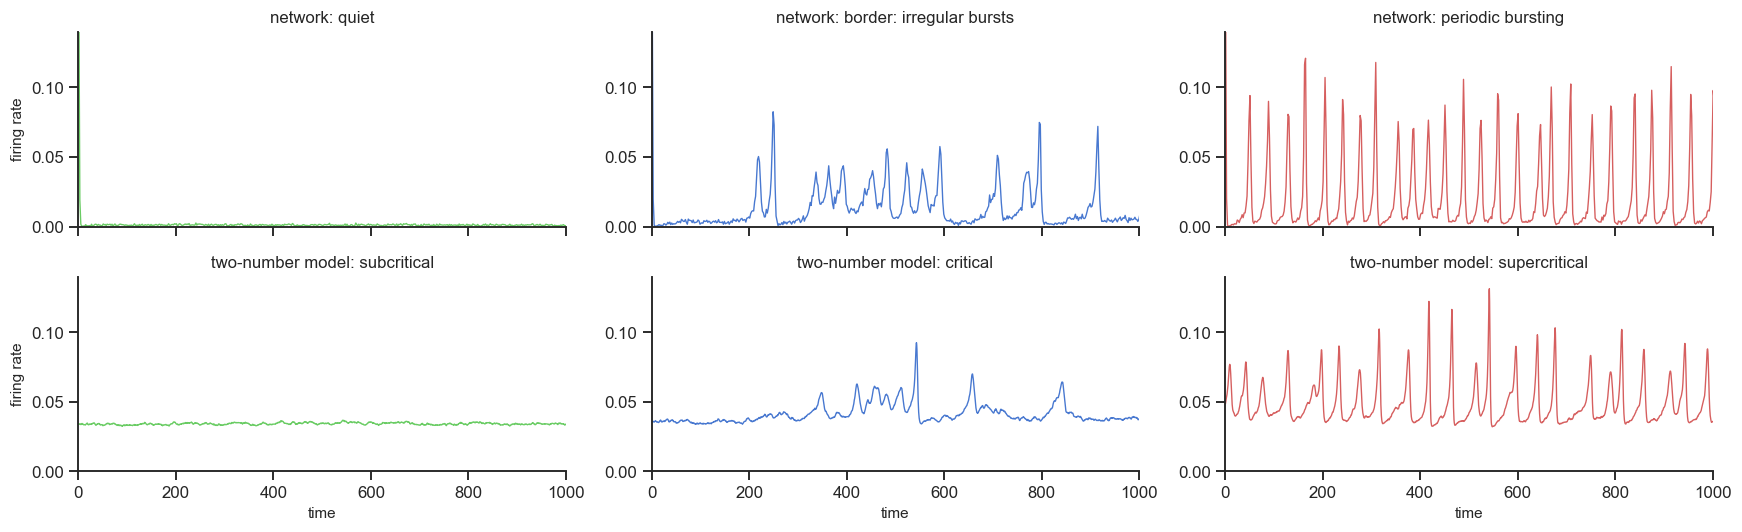

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(16, 5), sharex=True)
pairs = [("quiet", "subcritical"), ("border: irregular bursts", "critical"), ("periodic bursting", "supercritical")]
for j, (net_name, mf_name) in enumerate(pairs):
    key = MF[mf_name][1]
    t, Z, ph, *_ = NET[net_name]
    tr, rr = population_rate(t, ph, ph.shape[1])
    ax[0, j].plot(tr, rr, c=REG[key], lw=0.9); ax[0, j].set(title=f"network: {net_name}", ylim=(0, 0.14))
    tm, R, Psi, rate = mf_runs[mf_name]
    mm = tm > 200
    ax[1, j].plot(tm[mm] - 200, rate[mm], c=REG[key], lw=0.9); ax[1, j].set(title=f"two-number model: {mf_name}", ylim=(0, 0.14), xlabel="time")
ax[0, 0].set_ylabel("firing rate"); ax[1, 0].set_ylabel("firing rate")
for a_ in ax.flat: a_.set_xlim(0, 1000)
plt.tight_layout()

## 4. What is special about the border?

Two experiments with the two-number model, scanning the tilt.

1. **Without noise.** Does the population keep a rhythm by itself? We measure the size of the oscillation it
   settles into (0 = it settles into a steady state).
2. **With the small noise.** How slow and how large are its fluctuations? We measure the **autocorrelation** of
   $R$ (how similar the signal is to itself one time unit later: close to 1 = slow, persistent fluctuations) and
   its variance.

*(~10 s.)*

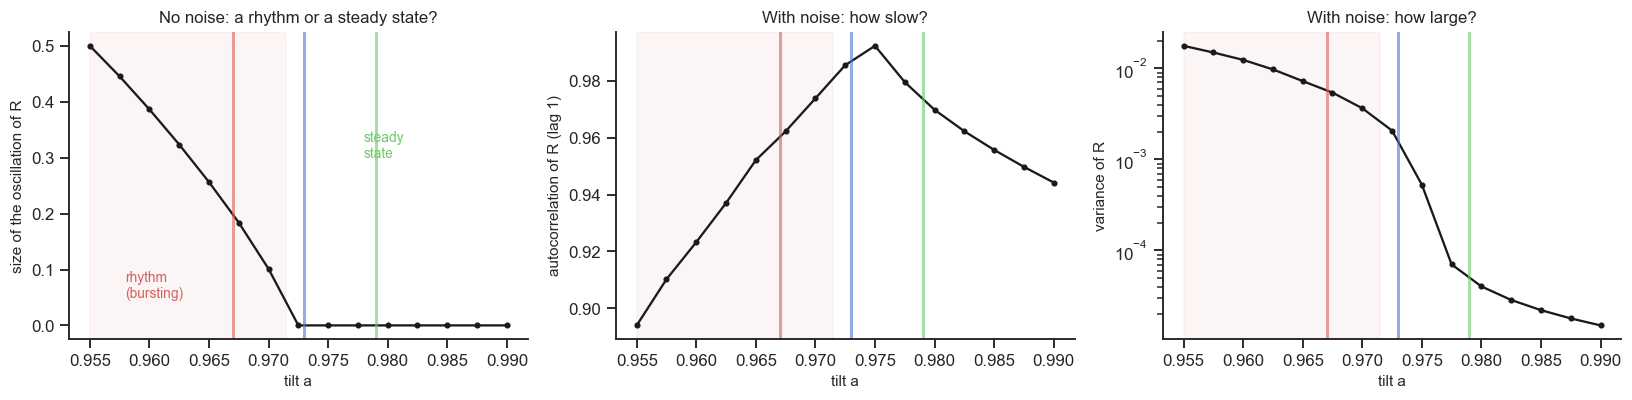

In [8]:
a_mf = np.round(np.arange(0.955, 0.9901, 0.0025), 4)
amp, ac1, var = [], [], []
for a in a_mf:
    t, R, Psi = meanfield.ott_antonsen_noisy(a=a, eta=0.0, T=3000, with_rate=False)       # no noise
    amp.append(R[-2000:].max() - R[-2000:].min())
    t, R, Psi = meanfield.ott_antonsen_noisy(a=a, T=20000, seed=1, with_rate=False)       # with noise
    x = R[t > 200] - R[t > 200].mean()
    ac1.append(np.mean(x[:-2] * x[2:]) / x.var())                                          # lag = 2 samples = 1 time unit
    var.append(x.var())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(a_mf, amp, "ko-", ms=3); ax[0].set(ylabel="size of the oscillation of R", title="No noise: a rhythm or a steady state?")
ax[1].plot(a_mf, ac1, "ko-", ms=3); ax[1].set(ylabel="autocorrelation of R (lag 1)", title="With noise: how slow?")
ax[2].plot(a_mf, var, "ko-", ms=3); ax[2].set(ylabel="variance of R", yscale="log", title="With noise: how large?")
for a_ in ax:
    a_.set_xlabel("tilt a")
    for name, (a, key) in MF.items():
        a_.axvline(a, c=REG[key], lw=2, alpha=0.6)
    a_.axvspan(a_mf[0], 0.9715, color=REG["super"], alpha=0.06)
ax[0].text(0.958, 0.05, "rhythm\n(bursting)", color=REG["super"], fontsize=9); ax[0].text(0.978, 0.3, "steady\nstate", color=REG["sub"], fontsize=9)
plt.tight_layout()

* **Left (no noise).** For small tilt the population keeps a **rhythm** by itself (periodic bursting), whose size
  shrinks as the tilt increases and vanishes near $a\approx0.971$. Beyond that point the population settles into a
  steady state. The border is where the rhythm is born: a **bifurcation** (Chapter 4, NB07).
* **Middle (with noise).** The autocorrelation is highest just on the quiet side of the border, at the critical
  value $a=0.973$ used in the paper. Close to the point where a rhythm is about to appear, the population responds to
  every small kick with a long, slow excursion before returning to rest. This slowing down near a transition is
  called **critical slowing down**. Rabuffo et al. use it (the autocorrelation peak) to define the critical regime.
* **Right.** The fluctuations grow by orders of magnitude from the subcritical to the supercritical side.

**Why this matters for brain models.** A brain region tuned near this border is quiet but **easy to tip**: inputs
from other regions can trigger bursts, or push it in or out of the bursting regime. In the whole-brain model of
Chapter 5 (NB09), and in Rabuffo et al. 2026, this is where the local populations reproduce brain-like large-scale
fluctuations best.

### Explore: tune the population

The two-number model (fast). The coloured lines on the slider correspond to the three values of the paper:
supercritical 0.967, critical 0.973, subcritical 0.979.

* Move the tilt from 0.99 down to 0.95. Where do the first bursts appear? When do they become regular?
* At $a=0.973$, increase the noise. Do the bursts become more frequent? Set the noise to 0: what is left?
* At $a=0.967$ (periodic bursting) set the noise to 0. Is the rhythm still there?
* Change the coupling $J$. Does the border move? In which direction?

In [9]:
@interact(a=slider(0.973, 0.94, 1.0, 0.001, "tilt a"),
          eta=slider(1.0, 0.0, 10.0, 0.25, "noise on the arrow (×1e-4)"),
          J=slider(1.25, 0.8, 1.6, 0.01, "coupling J"))
def explore_mean_field(a, eta, J):
    t, R, Psi, rate = meanfield.ott_antonsen_noisy(a=a, J=J, sigma=0.6725, eta=eta * 1e-4, T=2200, seed=3)
    m = t > 200
    fig, ax = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True)
    c = REG["super"] if a < 0.971 else (REG["crit"] if a < 0.976 else REG["sub"])
    ax[0].plot(t[m] - 200, rate[m], c=c, lw=0.9); ax[0].set(ylabel="firing rate", ylim=(0, max(0.1, 1.1 * rate[m].max())),
                                                          title=f"tilt a = {a}, noise {eta}e-4, coupling J = {J}")
    ax[1].plot(t[m] - 200, R[m], c=c, lw=0.9); ax[1].set(ylabel="arrow length R", xlabel="time", ylim=(0, 1))
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=0.973, continuous_update=False, description='tilt a', layout=Layout(wi…

## 5. Bursts of every duration at the border

Look again at the three runs of section 3. In the supercritical population every burst looks like the previous one;
in the critical population some bursts are tiny and some are long. Let us measure this. We call a **burst** each
stretch of time in which the firing rate is above its median value (the same definition Rabuffo et al. use for the
global signal of the whole-brain model), and measure how long each burst lasts. We collect many bursts from long
runs (one million time units for each regime, from the cache file).

ValueError: 
\mathdefault{10^{-2}}
^
ParseFatalException: Unknown symbol: \mathdefault, found '\'  (at char 0), (line:1, col:1)

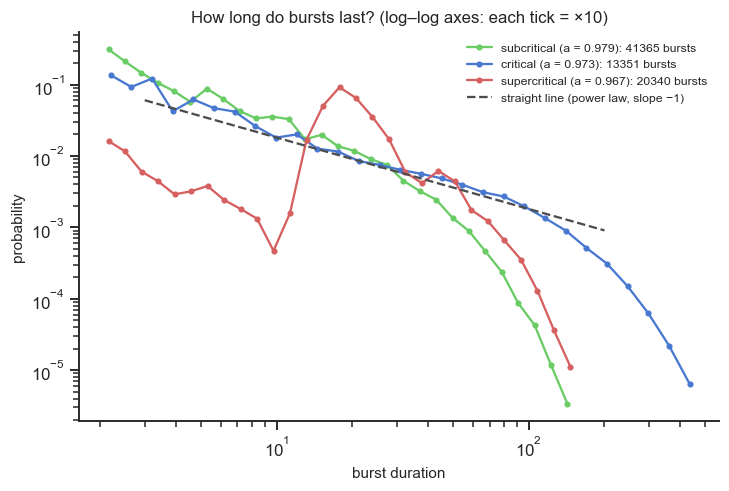

In [10]:
def burst_durations(rate, dt):
    above = np.r_[0, (rate > np.median(rate)).astype(int), 0]
    start, end = np.where(np.diff(above) == 1)[0], np.where(np.diff(above) == -1)[0]
    return (end - start) * dt

def log_hist(x, n_bins=30):
    edges = np.logspace(np.log10(x.min()), np.log10(x.max()), n_bins)
    h, _ = np.histogram(x, edges)
    centre = np.sqrt(edges[:-1] * edges[1:])
    ok = h > 0
    return centre[ok], (h / np.diff(edges) / len(x))[ok]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, (a, key) in MF.items():
    if f"durations_{name}" in scan:                     # long runs (10^6 time units) from data/cache/nb06_scan.npz
        D = scan[f"durations_{name}"]
    else:
        t, R, Psi, rate = meanfield.ott_antonsen_noisy(a=a, T=100_000, rec_dt=0.5, seed=1)
        D = burst_durations(rate[t > 200], 0.5)
    D = D[D >= 2]                                         # drop the tiniest excursions (noise crossing the median)
    x, P = log_hist(D)
    ax.plot(x, P, "o-", ms=3, c=REG[key], label=f"{name} (a = {a}): {len(D)} bursts")
    if name == "critical":
        x_crit, P_crit = x, P
xx = np.logspace(np.log10(3), np.log10(200), 10)
P10 = np.interp(np.log10(10), np.log10(x_crit), np.log10(P_crit))
ax.plot(xx, 10 ** P10 * (xx / 10) ** -1.0, "--", c="0.3", lw=1.5, label="straight line (power law, slope −1)")
ax.set(xscale="log", yscale="log", xlabel="burst duration", ylabel="probability",
       title="How long do bursts last? (log–log axes: each tick = ×10)")
ax.legend(fontsize=8)
plt.tight_layout()

* **Supercritical (red, periodic bursting):** a bump at one particular duration: the bursts of a rhythm all last
  about the same time. There is a **typical duration**.
* **Subcritical (green, quiet):** short excursions follow the same line as the critical ones, but the curve
  plunges after a few tens of time units: long bursts never happen.
* **Critical (blue, border):** bursts of all durations, from very short to very long (here up to a few hundred
  time units, several times longer than in the quiet population). On log–log axes the distribution stays close to
  a **straight line** from about 3 to 200 time units (dashed): there is **no typical duration**. (The line bends down
  at the far end, where bursts start to be as long as the slowest timescale of the population; real power laws
  always end somewhere.) A straight line on log–log axes
  is a **power law**.

Why a power law is interesting, and why it is a signature of a balanced population, is the subject of the next
notebook (NB06b), where we build the simplest possible model that produces one. There we will find the same
sequence of regimes as here: quiet, aperiodic bursts at the border, and a rhythm when excitation is strong.

## 6. Take-home

* A population of rotators can be summarised by **one arrow**: its length $R$ (how together the units are) and its
  direction (where they are). For excitable units, a long arrow means *quiet*, a dip means a *burst*.
* By changing excitability and noise, the **network** shows distinct regimes: quiet, periodic bursting,
  asynchronous firing, and at the border between quiet and bursting, **irregular bursts of different sizes**.
* A **two-number model** of the arrow (mean field) reproduces the sequence quiet → irregular bursts → periodic
  bursting, at a fraction of the cost. Its parameter values differ from the network's: it is tuned relative to its
  own transition.
* At the border the population is slow and easy to tip (**critical slowing down**). This is the working point chosen
  for the local populations of the whole-brain model (Chapter 5).
* At the border the bursts have **no typical duration** (a power law); in the rhythm they all look alike.
* **Next (NB06b):** the simplest model of a balanced network, and why power laws matter. Then Chapter 4:
  bifurcations (NB07) and the avalanches of the border regime in the spiking network (NB08).

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **The network's border.** Repeat the scan of section 2 with $\sigma=0.45$ and $\sigma=0.55$. Does the jump to
   silence move? Mark the three positions on the map of section 2.
2. **Size matters.** Run the border population ($a=1.07$, $\sigma=0.499$) with $N=500$, $2000$ and $8000$ units.
   How do the bursts change? Why does a small population burst more often? (Hint: fewer units means larger random
   fluctuations of the arrow.)
3. **Counting bursts.** In the two-number model, count the bursts (peaks of the firing rate above 0.1) in 5000 time
   units for $a$ between 0.96 and 0.98. Plot the number of bursts and the variability of the time between bursts.
   Where are the bursts regular, where irregular?
4. **Kicking the population.** In the two-number model without noise, start from the steady state at $a=0.973$ and
   at $a=0.99$ and give the arrow a small kick (start from a slightly shorter arrow, e.g. `R0=0.7`). How long does it
   take to return to rest in each case? Relate your answer to the autocorrelation of section 4.
5. **Map vs territory.** Compare the firing rates of the network (section 2) and of the two-number model
   (section 3) in the bursting regime: shape of a burst, time between bursts. What does the simplified model keep,
   and what does it change?

### References
* Shinomoto S, Kuramoto Y (1986). Phase transitions in active rotator systems. *Prog Theor Phys* 75:1105–1110.
* Buendía V, Villegas P, Burioni R, Muñoz MA (2021). Hybrid-type synchronization transitions: where incipient
  oscillations, scale-free avalanches, and bistability live together. *Phys Rev Research* 3:023224.
* Ott E, Antonsen TM (2008). Low dimensional behavior of large systems of globally coupled oscillators. *Chaos* 18:037113.
* Klinshov V, Franović I (2019). Two scenarios for the onset and suppression of collective oscillations in
  heterogeneous populations of active rotators. *Phys Rev E* 100:062211.
* Rabuffo G, Bozzo P, Nguyen B, et al. (2026). Connectome modulates critical brain dynamics across local and global
  scales. *Phys Rev Research* (accepted). Two-number active-rotator model as the local population of a whole-brain
  model; sub/critical/supercritical at $a = 0.979 / 0.973 / 0.967$.